In this notebook a "classical" supervised approach is applied. A fist cross-validation test is carried out on different tabular methods and then the best one is tuned to reach the best performances. A final study on the confidence thresholds of the best moodel is done.

# 00 - General Operations

In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split, cross_val_predict, ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score, classification_report, precision_score, recall_score
from tqdm import tqdm

sys.path.append(str(Path("../../src/utils").resolve()))
from dataset_balancing import balance_dataset

In [2]:
random_state = 42

families_dict = {
    # Neutral_Background
    "AlbedoPhotons" : "Neutral_Background",
    "AtmosphericNeutrons" : "Neutral_Background",
    "CosmicPhotons" : "Neutral_Background",

    # TEMP: tgf
    #"TGF": "Neutral_Background",
    "TGF" : "TGF",
    
    # EM_Primary 
    "PrimaryElectrons" : "EM_Primary",
    "PrimaryPositrons" : "EM_Primary",

    # EM_Secondary
    "SecondaryElectrons" : "EM_Secondary",
    "SecondaryPositrons" : "EM_Secondary",

    # Hadronic_Heavy
    "PrimaryProtons" : "Hadronic_Heavy",
    "PrimaryAlphas" : "Hadronic_Heavy",
    "SecondaryProtonsUpward" : "Hadronic_Heavy",
    "SecondaryProtonsDownward" : "Hadronic_Heavy"
}

train_size = 0.8


FAMILY_FLAG = True
BALANCING_FLAG = True
NAIVE_SEARCH = True
GRID_SEARCH = True
FINE_TUNE = True
target = "particle_family" if FAMILY_FLAG else "particle_type"


In [3]:
ds = pd.read_csv("../../data/Engineered_Datasets/bgtgf_ge3hit_dataset.csv")
print(f"Dataset shape: {ds.shape}")
print(f"Particle distribution:\n{ds['particle_type'].value_counts().to_string()}")

Dataset shape: (224816, 44)
Particle distribution:
particle_type
TGF                         141183
SecondaryPositrons           17141
PrimaryPositrons             14546
PrimaryProtons               12455
AlbedoPhotons                 8789
PrimaryAlphas                 7215
PrimaryElectrons              6464
SecondaryProtonsUpward        4594
SecondaryProtonsDownward      4256
SecondaryElectrons            4205
AtmosphericNeutrons           2043
CosmicPhotons                 1925


In [4]:
if FAMILY_FLAG:
    ds["particle_family"] = ds["particle_type"].map(families_dict)
    print(f"Family distribution:\n{ds['particle_family'].value_counts().to_string()}")
else: 
    print(f"Particle distribution:\n{ds["particle_type"].value_counts().to_string()}")

Family distribution:
particle_family
TGF                   141183
Hadronic_Heavy         28520
EM_Secondary           21346
EM_Primary             21010
Neutral_Background     12757


In [5]:
if BALANCING_FLAG:
    ds = balance_dataset(
        ds, target_col="particle_type", 
        n_samples=min(5000, ds["particle_type"].value_counts().min()), 
        random_state=random_state
    )
    print(f"Balanced dataset shape: {ds.shape}")
    print(f"Balanced particle distribution:\n{ds['particle_type'].value_counts().to_string()}")

dropping_features = ["pixel_ijk", "particle_type"]
if FAMILY_FLAG:
    dropping_features.append("particle_family")
    ds = balance_dataset(
        ds, target_col="particle_family", 
        n_samples=min(5000, ds["particle_family"].value_counts().min()), 
        random_state=random_state
    )
    print(f"Balanced dataset shape: {ds.shape}")
    print(f"Balanced particle distribution:\n{ds['particle_family'].value_counts().to_string()}")

y = ds[target]
X = ds.drop(columns=dropping_features)

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, train_size=train_size, stratify=y, random_state=42)
print(f"train {Xtrain.shape}, test {Xtest.shape}")

Balanced dataset shape: (23100, 45)
Balanced particle distribution:
particle_type
AlbedoPhotons               1925
AtmosphericNeutrons         1925
CosmicPhotons               1925
PrimaryAlphas               1925
PrimaryElectrons            1925
PrimaryPositrons            1925
PrimaryProtons              1925
SecondaryElectrons          1925
SecondaryPositrons          1925
SecondaryProtonsDownward    1925
SecondaryProtonsUpward      1925
TGF                         1925
Balanced dataset shape: (9625, 45)
Balanced particle distribution:
particle_family
EM_Primary            1925
EM_Secondary          1925
Hadronic_Heavy        1925
Neutral_Background    1925
TGF                   1925
train (7700, 42), test (1925, 42)


The dataset has 63% of events which are TGF. To avoid a classifier that learns the class prevalence, it is balanced by undersampling: first per particle type, then per family (9625 events in total, ~4% of the available data). The mix of particle types inside each family is also equalised. All the metrics below refer to a scenario with equal probability for the five families.

# 01 - Naive test on different models

In this section basic varsion of different models are compared in order to define the better one for the next steps. The comparison is done 5-fold cross-validation on the training set.

- **Dummy (most frequent)**: reference at chance level
- **Decision tree**: simple non-linear model (prone to overfitting).
- **Logistic regression**: linear baseline.
- **MLP** (128-64): small neural network on the same features.
- **HistGradientBoosting**: ensemble of trees, handles non-linear relations and feature interactions and needs no feature scaling.

In [6]:
models = {
    "Most frequent (dummy)": DummyClassifier(strategy="most_frequent", random_state=random_state),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=random_state),
    "Logistic Regression": make_pipeline(
        PowerTransformer(), 
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=random_state)
    ),
    "MLP": make_pipeline(
        PowerTransformer(),
        MLPClassifier(
            hidden_layer_sizes=(128, 64), 
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            max_iter=200, 
            random_state=random_state
        )
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.01, max_iter=500, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=random_state),
}

In [7]:
if NAIVE_SEARCH:
    folds = 5
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=random_state)
    rows = []
    for name, model in models.items():
        print(f"Processing {name}...")

        scores = cross_validate(model, Xtrain, ytrain, cv=cv, scoring=("f1_macro", "balanced_accuracy"))        
        # weight = compute_sample_weight("balanced", ytrain)     # weight for each event "like" class_weight="balanced"
        # scores = cross_validate(mlp, Xtrain, ytrain, cv=cv,
        #                         scoring=("f1_macro", "balanced_accuracy"),
        #                         params={"mlpclassifier__sample_weight": weight})
    
        rows.append({
            "model": name,
            "macro_F1":scores["test_f1_macro"].mean(), 
            "macro_F1_std": scores["test_f1_macro"].std(),
            "balanced_acc": scores["test_balanced_accuracy"].mean(),
        })

    print("=" * 50)
    df_cv = pd.DataFrame(rows).set_index("model")
    print(df_cv.round(3).to_string())

Processing Most frequent (dummy)...
Processing Decision Tree...
Processing Logistic Regression...
Processing MLP...
Processing Gradient Boosting...
                       macro_F1  macro_F1_std  balanced_acc
model                                                      
Most frequent (dummy)     0.067         0.000         0.200
Decision Tree             0.636         0.009         0.636
Logistic Regression       0.729         0.007         0.729
MLP                       0.730         0.012         0.731
Gradient Boosting         0.768         0.006         0.767


From the results presentend above we can see tath the best model is the HistGradienBoosting. So we will use it for the next steps.

In [8]:
best_model = models["Gradient Boosting"].fit(Xtrain, ytrain)
classes = list(best_model.classes_)
probs = best_model.predict_proba(Xtest)
ypred_naive = best_model.classes_[probs.argmax(1)]

print("HistGradientBoosting (NAIVE) on Test:")
print(f" - Macro F1: {f1_score(ytest, ypred_naive, average='macro'):.2f}")

HistGradientBoosting (NAIVE) on Test:
 - Macro F1: 0.77


                    precision    recall  f1-score   support

        EM_Primary      0.828     0.823     0.826       385
      EM_Secondary      0.658     0.696     0.677       385
    Hadronic_Heavy      0.830     0.784     0.806       385
Neutral_Background      0.739     0.691     0.714       385
               TGF      0.810     0.865     0.837       385

          accuracy                          0.772      1925
         macro avg      0.773     0.772     0.772      1925
      weighted avg      0.773     0.772     0.772      1925



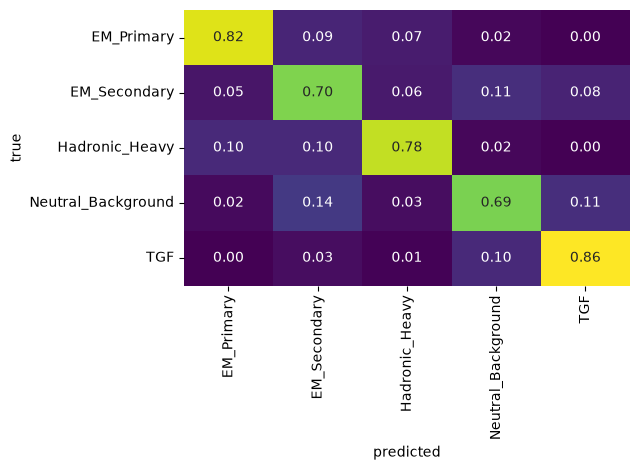

In [9]:
print(classification_report(ytest, ypred_naive, digits=3))
cm = pd.crosstab(ytest, ypred_naive, normalize="index").reindex(index=classes, columns=classes, fill_value=0)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis", ax=ax, cbar=False)
ax.set(xlabel="predicted", ylabel="true")
plt.tight_layout()
plt.show()

The resulst above shows a clear problem in classifying *EM_Secondary* and *Neutral_Background*.

# 02 - Fine Tunining Best Model

In this section we will fine tune the hyper-parameters of the HistGradientBoosting algorithm, the one with the best metrics of the section above.

In [10]:
parameters = {
    "learning_rate": [0.1, 0.05, 0.02],
    "max_leaf_nodes": [31, 63, 127],
    "l2_regularization": [0.0, 2.0],
    "min_samples_leaf": [50],  
    "max_iter": [400],
    "class_weight": ["balanced"],
    "early_stopping": [True],
    "validation_fraction": [0.1],
    "n_iter_no_change": [15],
    "random_state": [random_state],
}

# parameters = {
#     "learning_rate": [0.1, 0.01, 0.001],
#     "max_iter": [500],
#     "class_weight": ["balanced"],
#     "early_stopping": [True],
#     "validation_fraction": [0.1],
#     "n_iter_no_change": [20], 
#     "random_state": [random_state],
# }

pg = list(ParameterGrid(parameters))

Xtr, Xval, ytr, yval = train_test_split(
    Xtrain, ytrain, test_size=0.2, stratify=ytrain, random_state=random_state
)

In [11]:
if FINE_TUNE:
    tuning_results = []
    for params in tqdm(pg, desc="Hyper-parameters tuning"):

        clf = HistGradientBoostingClassifier(**params)
        clf.fit(Xtr, ytr)
        yval_pred = clf.predict(Xval)

        tuning_results.append({
            "learning_rate": params["learning_rate"],
            "max_leaf_nodes": params["max_leaf_nodes"],
            "l2_regularization": params["l2_regularization"],
            "n_iter_used": clf.n_iter_,
            "val_macro_F1": f1_score(yval, yval_pred, average="macro"),
            "val_balanced_acc": balanced_accuracy_score(yval, yval_pred),
            "best_params": params,
        })


    df_tuning = pd.DataFrame(tuning_results).sort_values(by="val_macro_F1", ascending=False)
    print(f"\n{df_tuning.iloc[0].best_params}")
    print("\n\nTop 5 Configurations:")
    df_tuning_show = df_tuning.drop(columns=["best_params"]).head(5).round(4)
    print(df_tuning_show)

Hyper-parameters tuning: 100%|██████████| 18/18 [04:54<00:00, 16.37s/it]


{'class_weight': 'balanced', 'early_stopping': True, 'l2_regularization': 0.0, 'learning_rate': 0.02, 'max_iter': 400, 'max_leaf_nodes': 127, 'min_samples_leaf': 50, 'n_iter_no_change': 15, 'random_state': 42, 'validation_fraction': 0.1}


Top 5 Configurations:
    learning_rate  max_leaf_nodes  l2_regularization  n_iter_used  \
8            0.02             127                0.0          207   
16           0.02              63                2.0          273   
4            0.05              63                0.0           97   
9            0.10              31                2.0           73   
15           0.02              31                2.0          262   

    val_macro_F1  val_balanced_acc  
8         0.7556            0.7552  
16        0.7530            0.7526  
4         0.7518            0.7519  
9         0.7515            0.7506  
15        0.7515            0.7506  


The best paramaters for the model are:
<br>
| Param | Value |
| :--- | :--- |
| `class_weight` | `'balanced'` |
| `early_stopping` | `True` |
| `l2_regularization` | `0.0` |
| `learning_rate` | `0.02` |
| `max_iter` | `400` |
| `max_leaf_nodes` | `127` |
| `min_samples_leaf` | `50` |
| `n_iter_no_change` | `15` |
| `random_state` | `42` |
| `validation_fraction` | `0.1` |

In [12]:
if FINE_TUNE:
    best_params = df_tuning.iloc[0]["best_params"]
    best_gb = HistGradientBoostingClassifier(**best_params)
else:
    best_gb = HistGradientBoostingClassifier(
        class_weight="balanced",
        early_stopping=True,
        l2_regularization=0.0,
        learning_rate=0.02,
        max_iter=400,
        max_leaf_nodes=127,
        min_samples_leaf=50,
        n_iter_no_change=15,
        random_state=random_state,
        validation_fraction=0.1
    )
best_gb.fit(Xtrain, ytrain)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.02
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",400
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",127
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",50
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",True
,"n_iter_no_change n_iter_no_change: int, default=10Used to determine when to ""early stop"". The fitting process isstopped when none of the last ``n_iter_no_change`` scores are betterthan the ``n_iter_no_change - 1`` -th-to-last one, up to sometolerance. Only used if early stopping is performed.",15
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0


## 02.1 - Results and tests on tuned model

First predict the values for the test set and print the metrics:

In [13]:
ypred_tuned = best_gb.predict(Xtest)
yprobs_final = best_gb.predict_proba(Xtest)

print(f"Test Macro-F1: {f1_score(ytest, ypred_tuned, average='macro'):.4f}")
print(f"Test Balanced Accuracy {balanced_accuracy_score(ytest, ypred_tuned):.4f}\n")
print(classification_report(ytest, ypred_tuned, digits=3))

Test Macro-F1: 0.7667
Test Balanced Accuracy 0.7673

                    precision    recall  f1-score   support

        EM_Primary      0.840     0.821     0.830       385
      EM_Secondary      0.642     0.675     0.658       385
    Hadronic_Heavy      0.822     0.805     0.814       385
Neutral_Background      0.746     0.662     0.702       385
               TGF      0.791     0.873     0.830       385

          accuracy                          0.767      1925
         macro avg      0.768     0.767     0.767      1925
      weighted avg      0.768     0.767     0.767      1925



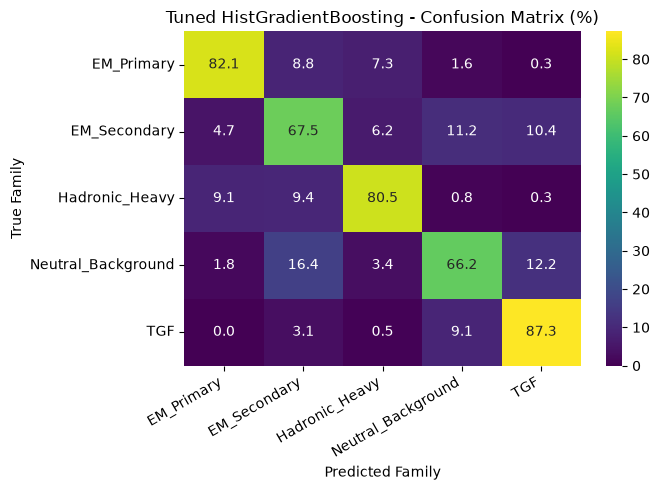

In [14]:
classes = list(best_gb.classes_)
cm = pd.crosstab(ytest, ypred_tuned, normalize="index").reindex(index=classes, columns=classes, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm * 100, annot=True, fmt=".1f", cmap="viridis", ax=ax, cbar=True)
ax.set(xlabel="Predicted Family", ylabel="True Family",title="Tuned HistGradientBoosting - Confusion Matrix (%)",)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
probs_oof = cross_val_predict(best_gb, X, y, cv=cv, method="predict_proba")
pred_oof = np.array(classes)[probs_oof.argmax(1)]

print(probs_oof.shape)
print(f"Out-of-Fold (oof) macro-F1: {f1_score(y, pred_oof, average='macro'):.3f}")
#print(y.value_counts().to_string())

(9625, 5)
Out-of-Fold (oof) macro-F1: 0.772


Print the most important feature for the classifier using the `permutation_importance` method which shuffles the value of a feature and analyze the drops of the metrics:

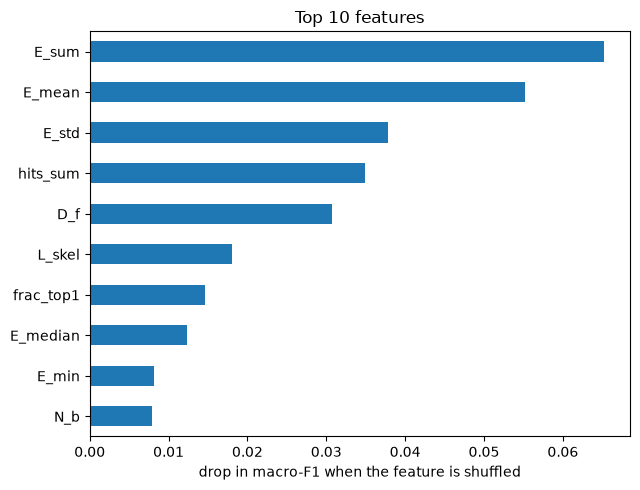

In [16]:
features = Xtrain.columns
perm_importance = permutation_importance(best_gb, Xtest, ytest, n_repeats=5, scoring="f1_macro", random_state=random_state, n_jobs=-1)
importance = pd.Series(perm_importance.importances_mean, index=features).sort_values(ascending=False)

N_FEAT_PLOT = 10
fig, ax = plt.subplots(figsize=(6.5, 5))
importance.head(N_FEAT_PLOT).iloc[::-1].plot.barh(ax=ax)
ax.set(xlabel="drop in macro-F1 when the feature is shuffled", title=f"Top {N_FEAT_PLOT} features")
plt.tight_layout() 
plt.show()

Permutation importance measures the drop in macro-F1 when a feature is shuffled. The most important features are energy-based (E_sum, E_mean...) and the number of hits. Then come the geometric features D_f (fractal dimension) and L_skel (skeleton length). N_b (number of branches) has a smaller effect.

Calculating SHAP values...


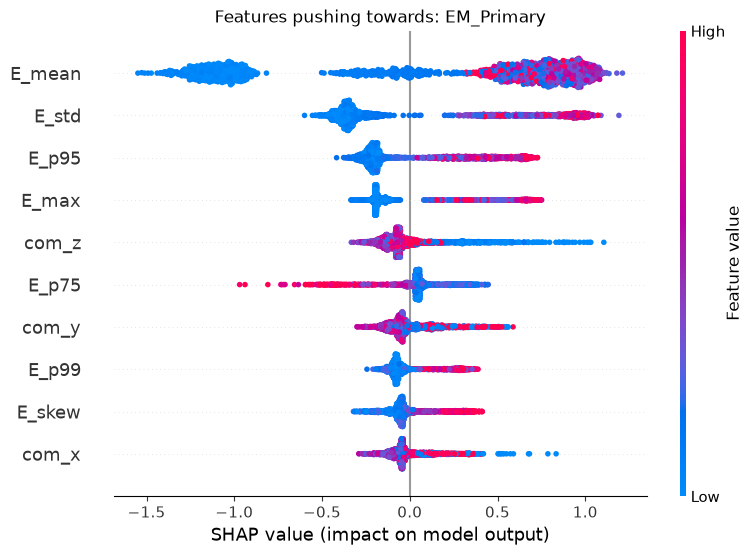

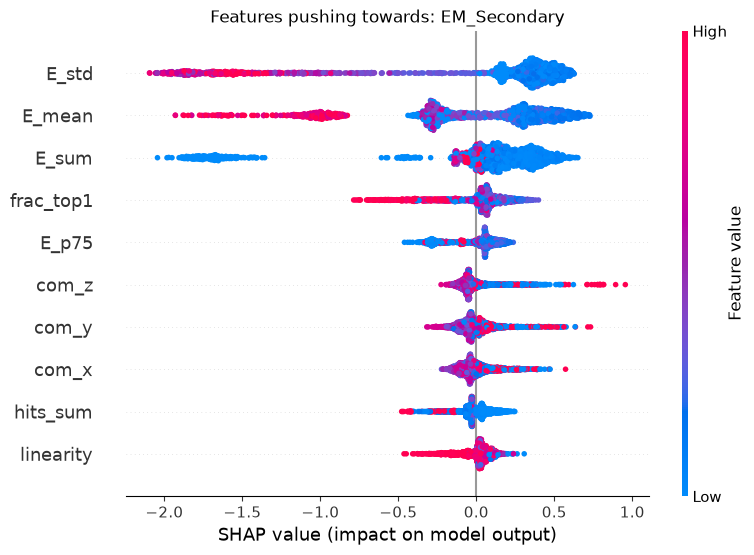

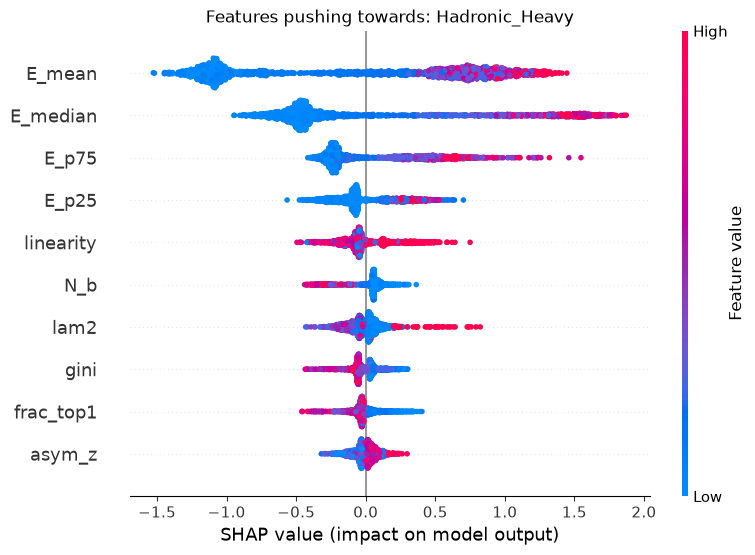

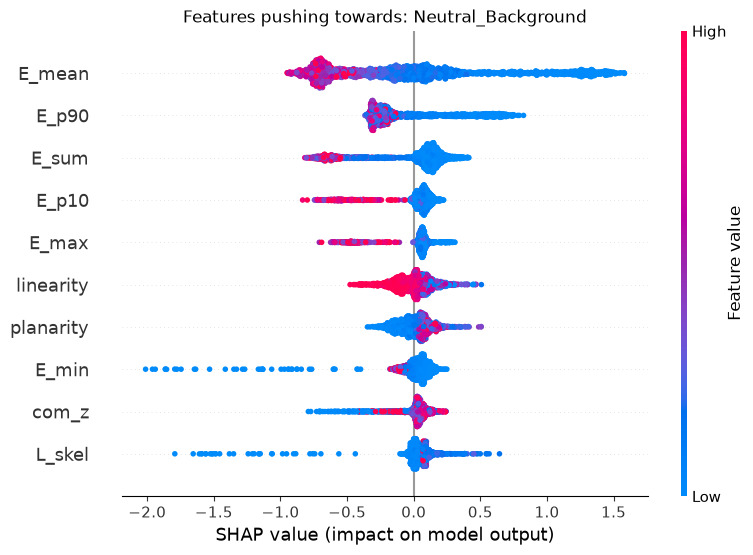

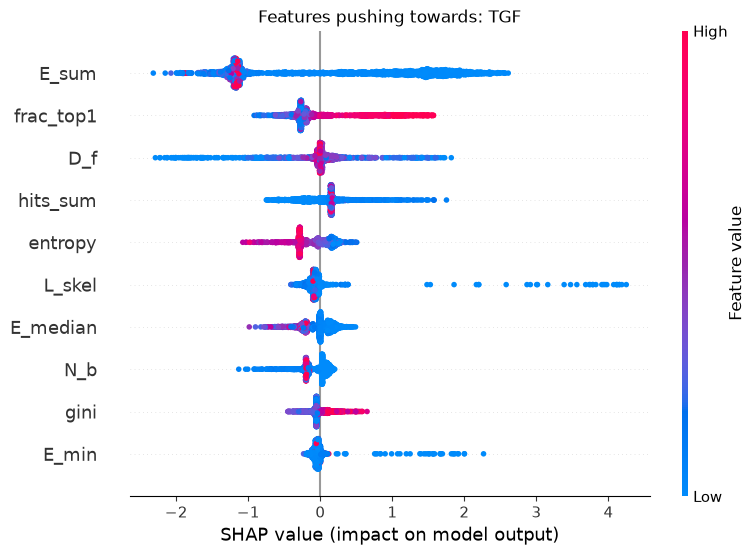

In [17]:
import shap

explainer = shap.TreeExplainer(best_gb)

print("Calculating SHAP values...")
shap_values = explainer.shap_values(Xtest)

for i, c in enumerate(best_gb.classes_):
    plt.Figure(figsize=(10, 8))
    sv_c = shap_values[:, :, i] if isinstance(shap_values, np.ndarray) else shap_values[i]
    shap.summary_plot(sv_c, Xtest, max_display=10, show=False)
    plt.title(f"Features pushing towards: {c}")
    plt.show()

- **EM_Primary**: high E_mean, E_std, E_p95 and E_max push towards the family; low E_mean pushes away. ß
- **EM_Secondary**: high E_std, E_mean and frac_top1 and high linearity push away als low total energy pushes away.
- **Hadronic_Heavy**: high E_mean, E_median, E_p75 and E_p25 push towards the family (high energy in every hit); high linearity pushes towards it, high N_b pushes away.
- **Neutral_Background**: high E_mean, E_p90, E_sum, E_p10, E_max and linearity push away.
- **TGF**: low E_sum pushes towards the family as high frac_top1; high entropy and N_b push away.

Let's see how the metrics change using different features:

missing: []
not in energy/topology groups: ['E_median', 'E_p10', 'E_p25', 'E_p75', 'E_p90', 'E_p95', 'E_p99', 'E_iqr', 'E_mad', 'E_skew', 'E_kurt', 'gini', 'frac_top3', 'com_x', 'com_y', 'com_z', 'rg', 'lam1', 'lam2', 'lam3', 'linearity', 'planarity', 'sphericity', 'asym_x', 'asym_y', 'asym_z', 'span_x', 'span_y', 'span_z', 'L_max_hops', 'L_max_metric']
energy only          ( 8 features)  macro-F1 = 0.708 +- 0.006
energy + topology    (11 features)  macro-F1 = 0.749 +- 0.006
all features         (42 features)  macro-F1 = 0.772 +- 0.006


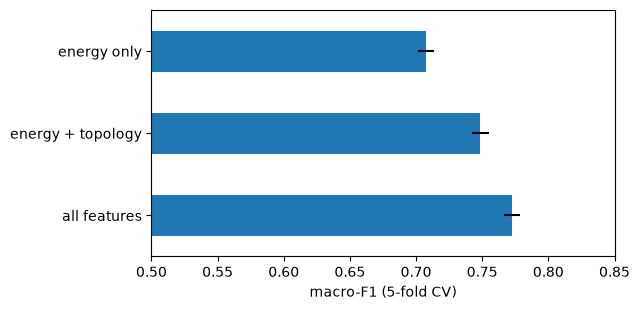

In [18]:
energy_cols = ["hits_sum", "E_sum", "E_mean", "E_max", "E_min", "E_std", "frac_top1", "entropy"]
topo_cols   = ["L_skel", "D_f", "N_b"]
all_cols    = list(X.columns)

print("missing:", [c for c in energy_cols + topo_cols if c not in X.columns])
print("not in energy/topology groups:", [c for c in all_cols if c not in energy_cols + topo_cols])

groups = {
    "energy only":         energy_cols,
    "energy + topology":   energy_cols + topo_cols,
    "all features":        all_cols,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
rows = []
for name, cols in groups.items():
    s = cross_validate(clone(best_gb), X[cols], y, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({
        "features": name, 
        "n_features": len(cols),
        "macro_F1": s["test_score"].mean(), 
        "std": s["test_score"].std()
    })
    print(f"{name:20s} ({len(cols):2d} features)  macro-F1 = {rows[-1]['macro_F1']:.3f} +- {rows[-1]['std']:.3f}")

df_abl = pd.DataFrame(rows).set_index("features")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
df_abl["macro_F1"].iloc[::-1].plot.barh(xerr=df_abl["std"].iloc[::-1], ax=ax, color="tab:blue")
ax.set_xlabel("macro-F1 (5-fold CV)"); ax.set_ylabel("")
ax.set_xlim(0.5, 0.85)
plt.tight_layout(); plt.show()

Energy carries most of the information, but the geometry of the hits is what helps to separate families with similar energy deposits.

Now we study the metrics change with respect to the number of hits of events:

     hits  n_events  bal_accuracy  macro_F1
0       3      2503         0.608     0.612
1       4      1378         0.630     0.634
2       5       949         0.669     0.673
3       6       718         0.748     0.756
4     7-8       927         0.749     0.751
5    9-12       951         0.751     0.755
6   13-20       710         0.685     0.729
7   21-30       368         0.616     0.628
8   31-40       213         0.602     0.624
9   41-50       173         0.625     0.628
10    >50       735         0.641     0.668


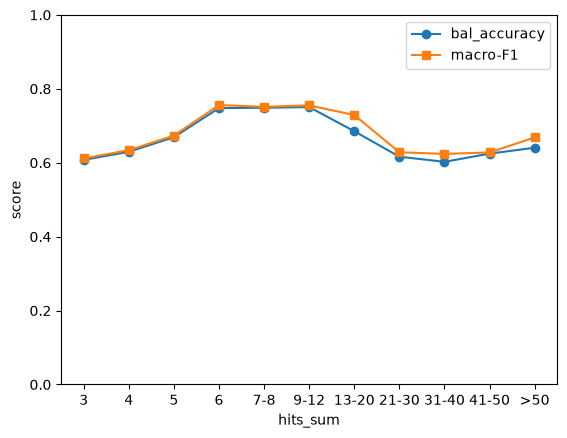

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
pred_oof = cross_val_predict(best_gb, X, y, cv=cv)          # best_gb is the tuned model

bins = pd.cut(X["hits_sum"], [2, 3, 4, 5, 6, 8, 12, 20, 30, 40, 50, np.inf],
              labels=["3", "4", "5", "6", "7-8", "9-12", "13-20", "21-30", "31-40", "41-50", ">50"])
y_arr = y.to_numpy()

res = []
for b in bins.cat.categories:
    m = (bins == b).to_numpy()
    res.append({
        "hits": b, "n_events": m.sum(),
        "bal_accuracy": balanced_accuracy_score(y_arr[m], pred_oof[m]),
        "macro_F1": f1_score(y_arr[m], pred_oof[m], average="macro")
    })
res = pd.DataFrame(res)
print(res.round(3))

plt.plot(res["hits"], res["bal_accuracy"], "o-", label="bal_accuracy")
plt.plot(res["hits"], res["macro_F1"], "s-", label="macro-F1")
plt.xlabel("hits_sum"); plt.ylabel("score"); plt.ylim(0, 1); plt.legend()
plt.show()

# hit_bins = pd.qcut(Xtest["hits_sum"], q=6, duplicates="drop")
# by_hits = (pd.Series(ypred_naive == ytest.to_numpy(), index=Xtest.index).groupby(hit_bins, observed=True).agg(accuracy="mean", n_events="size"))
# print("Accuracy by hits_sum:\n", by_hits.round(3).to_string())

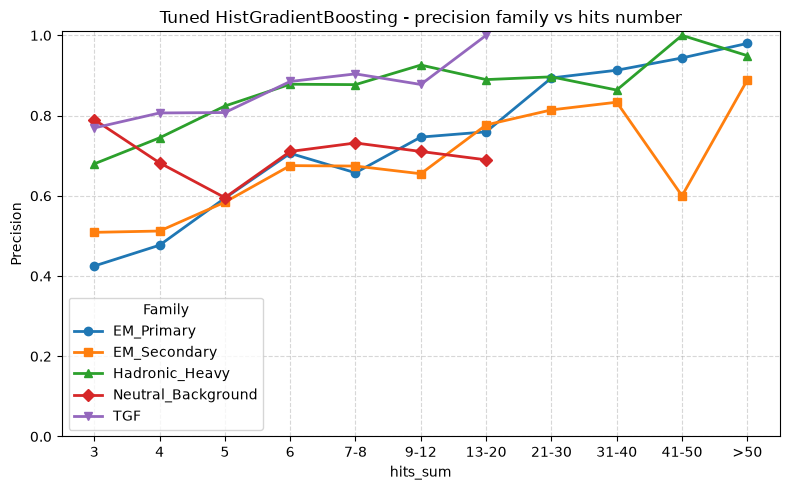

In [ ]:
METRIC = "precision"   # "precision" = quanto sono pure le assegnazioni a quella famiglia
                       # "recall"    = quanti eventi veri della famiglia vengono assegnati bene
 
metric_fn = precision_score if METRIC == "precision" else recall_score
hit_labels = list(bins.cat.categories)
 
fig, ax = plt.subplots(figsize=(8, 5))
for fam, marker in zip(classes, ["o", "s", "^", "D", "v"]):
    vals = []
    for b in hit_labels:
        m = (bins == b).to_numpy()
        vals.append(metric_fn(y[m] == fam, pred_oof[m] == fam, zero_division=np.nan))
    ax.plot(hit_labels, vals, marker=marker, lw=2, label=fam)

ax.set(
    xlabel="hits_sum", 
    ylabel=METRIC.capitalize(),  
    ylim=(0.0, 1.01),
    title=f"Tuned HistGradientBoosting - {METRIC} family vs hits number"
)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Family")
plt.tight_layout()
plt.show()

In [21]:
pd.crosstab(bins, y)

particle_family,EM_Primary,EM_Secondary,Hadronic_Heavy,Neutral_Background,TGF
hits_sum,,,,,
3,89,406,295,1000,713
4,91,241,254,332,460
5,78,202,234,159,276
6,56,170,196,100,196
7-8,102,223,296,131,175
9-12,153,262,311,133,92
13-20,208,260,169,60,13
21-30,219,103,40,6,0
31-40,151,33,28,1,0


TGF and Neutral_Background have almost no events above 20 hits and the model never predicts them there, so macro-F1 is computed on only three families.

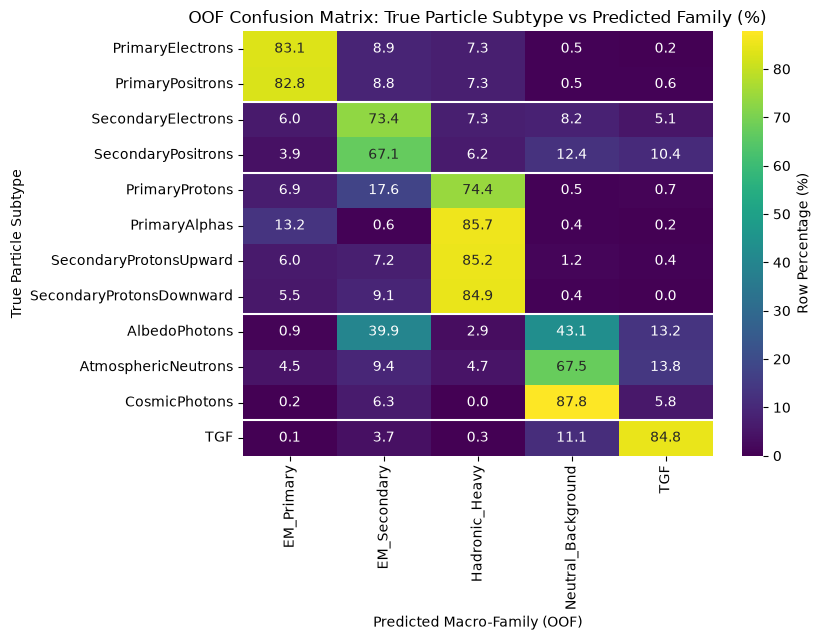

In [22]:
# 1. Ordina i particle_type reali raggruppandoli per famiglia fisica
ordered_types = [
    # EM_Primary
    "PrimaryElectrons",
    "PrimaryPositrons",
    # EM_Secondary
    "SecondaryElectrons",
    "SecondaryPositrons",
    # Hadronic_Heavy
    "PrimaryProtons",
    "PrimaryAlphas",
    "SecondaryProtonsUpward",
    "SecondaryProtonsDownward",
    # Neutral_Background
    "AlbedoPhotons",
    "AtmosphericNeutrons",
    "CosmicPhotons",
    # TGF
    "TGF",
]
# # Filtra solo quelli effettivamente presenti in ds
# ordered_types = [
#     p for p in ordered_types if p in ds["particle_type"].unique()
# ]

# 2. Costruisci la matrice di confusione OOF normalizzata per riga (%)
# Nota: usa pred_oof (calcolato al punto [15]) oppure ricalcolalo con best_gb
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
probs_oof_tuned = cross_val_predict(
    best_gb, X, y, cv=cv, method="predict_proba"
)
pred_oof_tuned = best_gb.classes_[probs_oof_tuned.argmax(1)]

cm_subtypes = (
    pd.crosstab(
        ds["particle_type"],
        pd.Series(pred_oof_tuned, index=ds.index, name="predicted_family"),
        normalize="index",
    ).reindex(index=ordered_types, columns=best_gb.classes_, fill_value=0)
    * 100
)

# 3. Plot della heatmap
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(
    cm_subtypes,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    ax=ax,
    cbar_kws={"label": "Row Percentage (%)"},
)

# Linee orizzontali per separare visivamente le macro-famiglie
for sep in [2, 4, 8, 11]:
  ax.axhline(sep, color="white", lw=1.5)

ax.set(
    xlabel="Predicted Macro-Family (OOF)",
    ylabel="True Particle Subtype",
    title=(
        "OOF Confusion Matrix: True Particle Subtype vs Predicted Family (%)"
    ),
)
plt.tight_layout()
plt.show()

As we can see from the above confusion matrix, the main cause of the missclassification of the Neutral Background family are the Albedo Photons particle wchich are splittend in EM_Secondary, TGF and Neutral Background. 

# 03 - Confidence treshold analisys

Choose a threshold for the confidence of probs to analize:

In [23]:
CONF_THRESH = 0.90

In [24]:
yprobs = best_gb.predict_proba(Xtest)
ypred = best_gb.classes_[yprobs.argmax(axis=1)]
max_probs = yprobs.max(axis=1)

thresholds = [0.0, 0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.98, 0.99]
conf_rows = []

for thr in thresholds:
  mask = max_probs >= thr
  n_kept = mask.sum()
  coverage = (n_kept / len(ytest)) * 100

  if n_kept > 0 and len(np.unique(ytest[mask])) == len(best_gb.classes_):
    macro_f1 = f1_score(ytest[mask], ypred[mask], average="macro")
    bal_acc = balanced_accuracy_score(ytest[mask], ypred[mask])
    acc = accuracy_score(ytest[mask], ypred[mask])
  else:
    macro_f1, bal_acc, acc = np.nan, np.nan, np.nan

  conf_rows.append({
      "Threshold": thr,
      "Events_Kept": n_kept,
      "Coverage_%": round(coverage, 1),
      "Macro_F1": round(macro_f1, 4),
      "Balanced_Acc": round(bal_acc, 4),
      "Accuracy": round(acc, 4),
  })

df_conf = pd.DataFrame(conf_rows)
print(f"Tot. event in test set: {Xtest.shape[0]}")
df_conf

Tot. event in test set: 1925


,Threshold,Events_Kept,Coverage_%,Macro_F1,Balanced_Acc,Accuracy
0,0.00,1925,100.0,0.7667,0.7673,0.7673
1,0.50,1743,90.5,0.8060,0.8064,0.8090
2,0.60,1529,79.4,0.8471,0.8470,0.8528
3,0.70,1323,68.7,0.8886,0.8889,0.8964
4,0.75,1207,62.7,0.9171,0.9174,0.9246
5,0.80,1096,56.9,0.9302,0.9296,0.9389
6,0.85,986,51.2,0.9434,0.9408,0.9544
7,0.90,849,44.1,0.9579,0.9542,0.9670
8,0.95,668,34.7,0.9748,0.9775,0.9835
9,0.98,439,22.8,0.9951,0.9934,0.9954


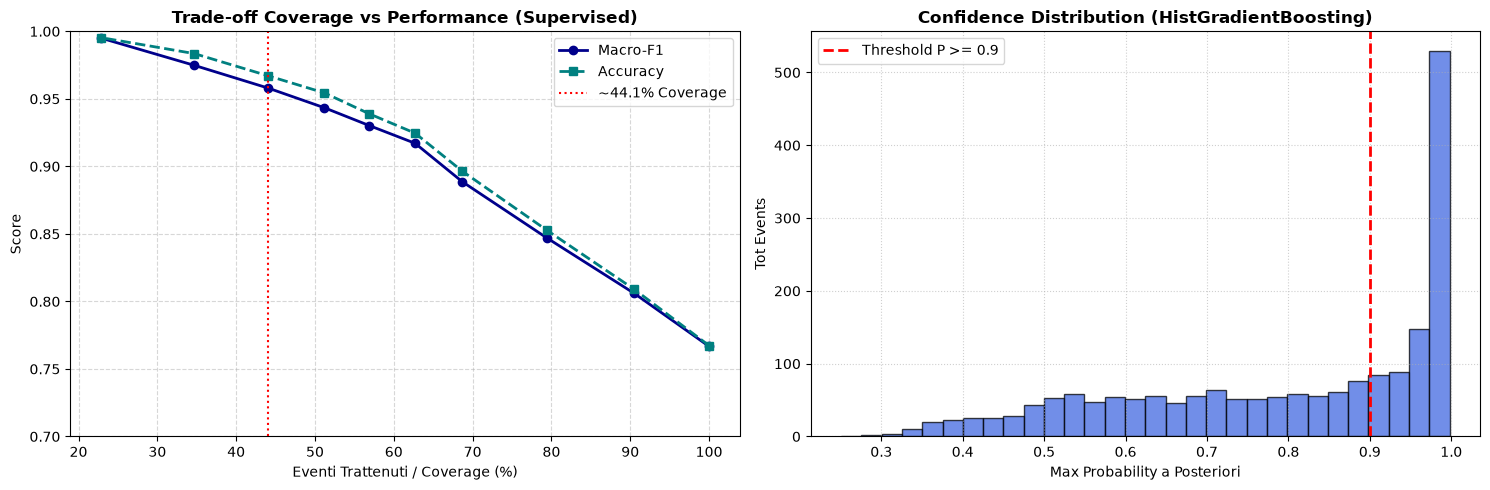

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

### Grafico 1: Trade-off Coverage vs Score
axes[0].plot(
    df_conf["Coverage_%"],
    df_conf["Macro_F1"],
    "o-",
    lw=2,
    color="darkblue",
    label="Macro-F1",
)
axes[0].plot(
    df_conf["Coverage_%"],
    df_conf["Accuracy"],
    "s--",
    lw=2,
    color="teal",
    label="Accuracy",
)
events_coverage = df_conf.loc[df_conf["Threshold"] == CONF_THRESH, "Coverage_%"].iloc[0]
# print(events_coverage)
axes[0].axvline(events_coverage, color="red", linestyle=":", lw=1.5, label=f"~{events_coverage}% Coverage")
axes[0].set_title("Trade-off Coverage vs Performance (Supervised)", fontweight="bold")
axes[0].set_xlabel("Events kept / Coverage (%)")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.70, 1.0)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

### Grafico 2: Istogramma delle probabilità massime (confrontabile con Confidence Distribution GMM)
axes[1].hist(max_probs, bins=30, color="royalblue", edgecolor="black", alpha=0.75)
axes[1].axvline(CONF_THRESH, color="red", linestyle="--", lw=2, label=f"Threshold P >= {CONF_THRESH}")
axes[1].set_title("Confidence Distribution (HistGradientBoosting)", fontweight="bold")
axes[1].set_xlabel("Max Probability a Posteriori")
axes[1].set_ylabel("Tot Events")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

Events kept (in confidence threshold 0.9): 849 / 1925 (44.1%)

                    precision    recall  f1-score   support

        EM_Primary      0.944     0.987     0.965       239
      EM_Secondary      0.918     0.882     0.900        51
    Hadronic_Heavy      0.972     0.951     0.961       223
Neutral_Background      0.981     0.962     0.971       157
               TGF      0.994     0.989     0.992       179

          accuracy                          0.967       849
         macro avg      0.962     0.954     0.958       849
      weighted avg      0.967     0.967     0.967       849



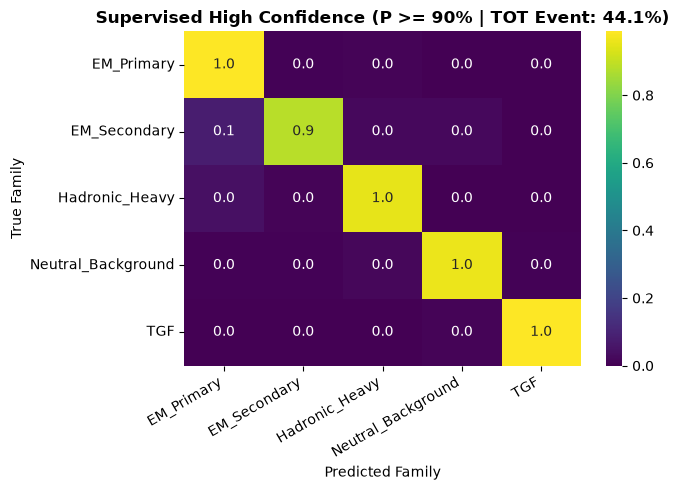

In [26]:
mask_hc = max_probs >= CONF_THRESH

print(f"Events kept (in confidence threshold {CONF_THRESH}): {mask_hc.sum()} / {len(ytest)} ({mask_hc.mean()*100:.1f}%)\n")
print(classification_report(ytest[mask_hc], ypred[mask_hc], digits=3))

# Matrice di confusione normalizzata
cm = pd.crosstab(ytest[mask_hc], ypred[mask_hc], normalize="index").reindex(index=classes, columns=classes, fill_value=0)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt=".1f", cmap="viridis", cbar=True)
plt.title(
    f"Supervised High Confidence (P >= {int(CONF_THRESH*100)}% | TOT Event:"
    f" {mask_hc.mean()*100:.1f}%)",
    fontweight="bold",
)
plt.xlabel("Predicted Family")
plt.ylabel("True Family")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Keeping only events with maximum class probability above a threshold trades coverage for quality.

The distribution of the maximum probability has a large peak close to 1 and a flat tail between 0.3 and 0.9: the model is very confident on about a third of the events and uncertain on the rest.

The precision curves show that TGF reaches ≥ 0.99 precision already at P ≥ 0.8, while EM_Secondary needs ≥ 0.9 to exceed 0.9.

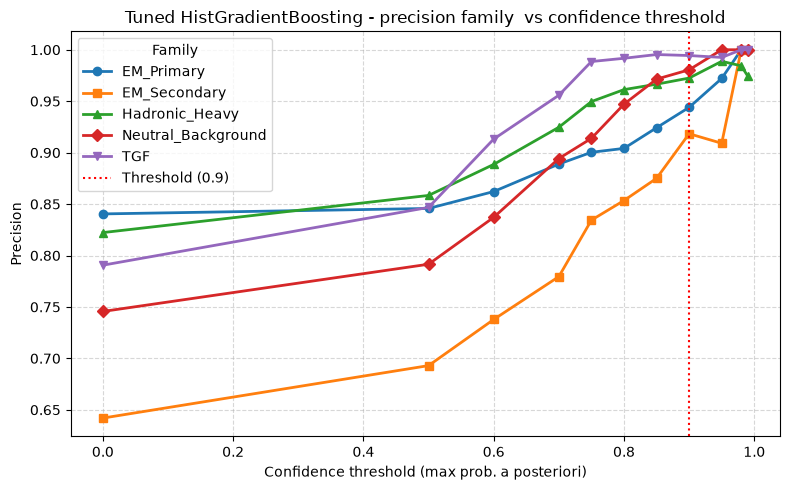

In [27]:
METRIC = "precision"   # "precision" or "recall"
metric_fn = precision_score if METRIC == "precision" else recall_score
 
yt_all = np.asarray(ytest)
yp_all = np.asarray(ypred)
 
fig, ax = plt.subplots(figsize=(8, 5))
for fam, marker in zip(classes, ["o", "s", "^", "D", "v"]):
    vals = []
    for thr in thresholds:
        m = max_probs >= thr
        vals.append(metric_fn(yt_all[m] == fam, yp_all[m] == fam, zero_division=np.nan)
                    if m.any() else np.nan)
    ax.plot(thresholds, vals, marker=marker, lw=2, label=fam)
 
ax.axvline(CONF_THRESH, color="red", linestyle=":", lw=1.5, label=f"Threshold ({CONF_THRESH})")
ax.set(
    xlabel="Confidence threshold (max prob. a posteriori)", 
    ylabel=METRIC.capitalize(),
    title=f"Tuned HistGradientBoosting - {METRIC} family  vs confidence threshold"
)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Family")
plt.tight_layout()
plt.show()
 


# 04 - Conclusions

The supervised approach with classical (tabular) ML methods shows improvment in "family" isolation wrt to clustering. The unsupervised study results helpful in identifying the _family_ (macro group) used in this section. 

Best results are obtained using high confidence threshold ($\ge 80$%) but the drawback is a significant unclassified portion of data. It is mandatory to choose between high accuracy with a significant number of discarded event OR low accuracy but every event is considered.

References:
 - Hist Gradient Boosting: https://www.geeksforgeeks.org/machine-learning/histgradientboostingclassifier-in-sklearn/